# Historical water reference: separating common water from unexplained water

We use JRC water occurrence (1984–2021), which predates this 2022 scene. **Occurrence ≥90%** is an exploratory high-frequency-water rule, not a verified permanent-water definition. Native resolution is 30m; nearest-neighbour alignment to 10m does not add detail.

Predicted water outside that reference can include seasonal water, shoreline misalignment, model false positives, historical changes, or flooding. Locations with masked reference values are kept as a separate category; JRC masks include places where water was never detected, so absence is not proof of adequate dry observations. Do not call orange/purple pixels confirmed flood extent. Independent labels and event/dry-season comparisons remain necessary.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))


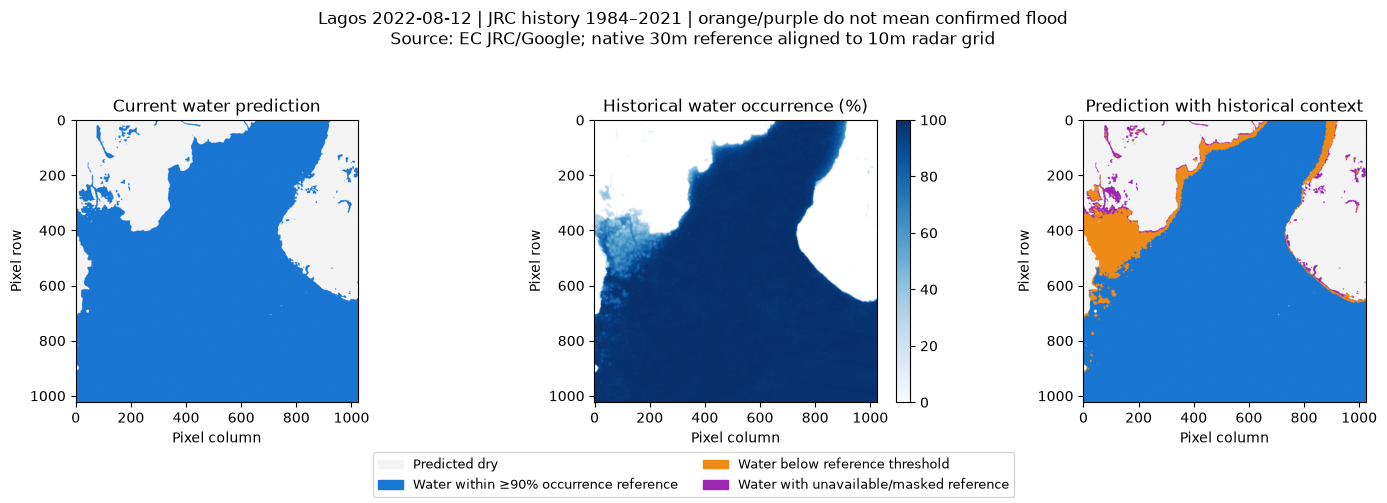

{
  "source": "JRC/GSW1_4/GlobalSurfaceWater",
  "band": "occurrence",
  "period": "1984-2021",
  "attribution": "Source: EC JRC/Google",
  "native_resolution_m": 30,
  "aligned_grid": {
    "crs": "EPSG:32631",
    "crs_transform": [
      10,
      0,
      544630,
      0,
      -10,
      729150
    ],
    "dimensions": [
      1024,
      1024
    ],
    "format": "GEO_TIFF"
  },
  "resampling": "Earth Engine default nearest neighbour; 10m alignment does not add source detail",
  "reference_threshold_percent": 90,
  "mask_sha256": "1f946d41e5f8fc647732f4b874d5354d14d1728218bf37fca4f7d27e89ff1189",
  "reference_sha256": "eb2a5417f8cd30404d0e8a74f69c9119035d8b49a11e43d0a4ea7d3e021311ea",
  "counts": {
    "0": 267672,
    "1": 694273,
    "2": 68565,
    "3": 18066,
    "255": 0
  },
  "meaning": "Exploratory high-frequency-water exclusion; outside-reference pixels are not confirmed flooding",
  "unavailable": "255 includes masked locations where JRC never detected water; absence is

In [2]:
import json
import shutil
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

source = PROJECT / "data/references/lagos_jrc"
out = PROJECT / "reports/lagos_2022/water_reference"
out.mkdir(exist_ok=True)
shutil.copy2(source / "reference.json", out / "reference.json")
with rasterio.open(source / "historical_occurrence.tif") as src:
    occurrence = src.read(1,masked=True)
    grid = src.transform, src.crs, src.shape
with rasterio.open(source / "water_context.tif") as src:
    assert (src.transform,src.crs,src.shape) == grid
    context = src.read(1,masked=True)
with rasterio.open(PROJECT / "data/predictions/lagos_2022/halo_64/water_mask.tif") as src:
    assert (src.transform,src.crs,src.shape) == grid
    water = src.read(1,masked=True)
report = json.loads((source / "reference.json").read_text())
assert sum(report["counts"].values()) == context.size
assert sum(report["counts"][k] for k in ["1","2","3"]) == int((water==1).sum())
fig,axes=plt.subplots(1,3,figsize=(15,5))
axes[0].imshow(water,cmap=ListedColormap(["#f4f4f4","#1976d2"]),vmin=0,vmax=1)
axes[0].set_title("Current water prediction")
image=axes[1].imshow(occurrence,cmap="Blues",vmin=0,vmax=100)
axes[1].set_title("Historical water occurrence (%)")
fig.colorbar(image,ax=axes[1],fraction=0.046)
colors=["#f4f4f4","#1976d2","#ef8a17","#9c27b0"]
axes[2].imshow(context,cmap=ListedColormap(colors),norm=BoundaryNorm([-0.5,0.5,1.5,2.5,3.5],4))
axes[2].set_title("Prediction with historical context")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=colors[i],label=label) for i,label in enumerate([
    "Predicted dry", "Water within ≥90% occurrence reference", "Water below reference threshold", "Water with unavailable/masked reference"])],
    loc="lower center",ncol=2,fontsize=9)
for ax in axes:ax.set_xlabel("Pixel column");ax.set_ylabel("Pixel row")
fig.suptitle("Lagos 2022-08-12 | JRC history 1984–2021 | orange/purple do not mean confirmed flood\nSource: EC JRC/Google; native 30m reference aligned to 10m radar grid")
fig.tight_layout(rect=[0,0.12,1,0.90]);fig.savefig(out/"historical_water_context.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)
print(json.dumps(report,indent=2))
